In [ ]:
import zipfile
import os

zip_path = "/content/archive.zip"
extract_path = "/content/olist_data"
with zipfile.ZipFile(zip_path, "r") as zip_ref:
   zip_ref.extractall(extract_path)
print(" Files Extracted Successfully")
print(os.listdir(extract_path))

 Files Extracted Successfully
['olist_order_reviews_dataset.csv', 'olist_sellers_dataset.csv', 'product_category_name_translation.csv', 'olist_geolocation_dataset.csv', 'olist_orders_dataset.csv', 'olist_customers_dataset.csv', 'olist_order_items_dataset.csv', 'olist_products_dataset.csv', 'olist_order_payments_dataset.csv']


In [ ]:
import os
import pandas as pd
extract_path = "/content/olist_data"
print(os.listdir(extract_path))


['olist_order_reviews_dataset.csv', 'olist_sellers_dataset.csv', 'product_category_name_translation.csv', 'olist_geolocation_dataset.csv', 'olist_orders_dataset.csv', 'olist_customers_dataset.csv', 'olist_order_items_dataset.csv', 'olist_products_dataset.csv', 'olist_order_payments_dataset.csv']


In [ ]:
import os
for file in os.listdir("/content/olist_data"):
  if file.endswith(".csv"):
    print(file)

olist_order_reviews_dataset.csv
olist_sellers_dataset.csv
product_category_name_translation.csv
olist_geolocation_dataset.csv
olist_orders_dataset.csv
olist_customers_dataset.csv
olist_order_items_dataset.csv
olist_products_dataset.csv
olist_order_payments_dataset.csv


In [ ]:
import pandas as pd
base = "/content/olist_data/"
orders = pd.read_csv(base + "olist_orders_dataset.csv")
products = pd.read_csv(base + "olist_products_dataset.csv")
reviews = pd.read_csv(base + "olist_order_reviews_dataset.csv")
print("Orders:", orders.shape)
print("Products:", products.shape)
print("Reviews:", reviews.shape)

Orders: (99441, 8)
Products: (32951, 9)
Reviews: (99224, 7)


In [ ]:
datasets = {
    "Orders": orders,
    "Products": products,
    "Reviews": reviews
}
for name, df in datasets.items():
  print(f"\n--- {name} ---")
  print("Missing values by column :")
  print(df.isnull().sum())



--- Orders ---
Missing values by column :
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

--- Products ---
Missing values by column :
product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

--- Reviews ---
Missing values by column :
review_id                      0
order_id                       0
review_score                   0
review_comment_title       87656
review_comment_message     58247
review_creation_date           0
review_answer_timestamp        0
d

In [ ]:
print("Orders duplicates:",orders.duplicated().sum())
print("Products duplicates:",products.duplicated().sum())
print("Reviews duplicates:",reviews.duplicated().sum())

Orders duplicates: 0
Products duplicates: 0
Reviews duplicates: 0


In [ ]:
print("ORDERS")
print(orders.isnull().sum())
print("\nPRODUCTS")
print(products.isnull().sum())
print("\nREVIEWS")
print(reviews.isnull().sum())

ORDERS
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

PRODUCTS
product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

REVIEWS
review_id                      0
order_id                       0
review_score                   0
review_comment_title       87656
review_comment_message     58247
review_creation_date           0
review_answer_timestamp        0
dtype: int64


In [ ]:
print(orders["order_status"].value_counts())


order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64


In [ ]:
orders["order_purchase_timestamp"] = pd.to_datetime(
    orders["order_purchase_timestamp"],
    errors="coerce"
)
monthly_orders = (
    orders.dropna(subset=["order_purchase_timestamp"])
    .set_index("order_purchase_timestamp")
    .resample("MS")["order_id"]
    .count()
)
print(monthly_orders)

order_purchase_timestamp
2016-09-01       4
2016-10-01     324
2016-11-01       0
2016-12-01       1
2017-01-01     800
2017-02-01    1780
2017-03-01    2682
2017-04-01    2404
2017-05-01    3700
2017-06-01    3245
2017-07-01    4026
2017-08-01    4331
2017-09-01    4285
2017-10-01    4631
2017-11-01    7544
2017-12-01    5673
2018-01-01    7269
2018-02-01    6728
2018-03-01    7211
2018-04-01    6939
2018-05-01    6873
2018-06-01    6167
2018-07-01    6292
2018-08-01    6512
2018-09-01      16
2018-10-01       4
Freq: MS, Name: order_id, dtype: int64


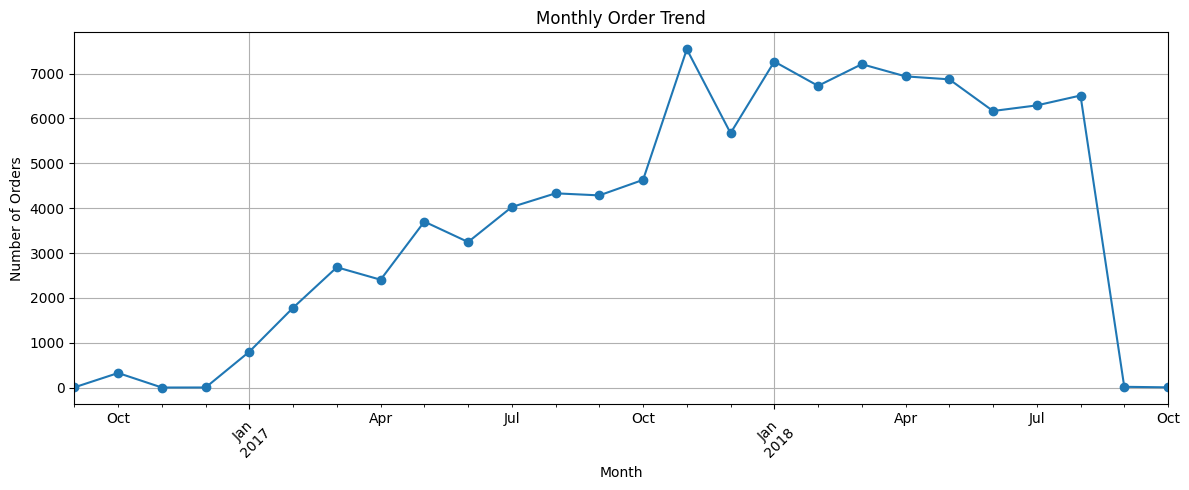

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
monthly_orders.plot(kind="line", marker="o")

plt.title("Monthly Order Trend")
plt.xlabel("Month")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
order_items = pd.read_csv(
    "/content/olist_data/olist_order_items_dataset.csv"
)
print(order_items.head())
print("Rows and columns:", order_items.shape)

                           order_id  order_item_id  \
0  00010242fe8c5a6d1ba2dd792cb16214              1   
1  00018f77f2f0320c557190d7a144bdd3              1   
2  000229ec398224ef6ca0657da4fc703e              1   
3  00024acbcdf0a6daa1e931b038114c75              1   
4  00042b26cf59d7ce69dfabb4e55b4fd9              1   

                         product_id                         seller_id  \
0  4244733e06e7ecb4970a6e2683c13e61  48436dade18ac8b2bce089ec2a041202   
1  e5f2d52b802189ee658865ca93d83a8f  dd7ddc04e1b6c2c614352b383efe2d36   
2  c777355d18b72b67abbeef9df44fd0fd  5b51032eddd242adc84c38acab88f23d   
3  7634da152a4610f1595efa32f14722fc  9d7a1d34a5052409006425275ba1c2b4   
4  ac6c3623068f30de03045865e4e10089  df560393f3a51e74553ab94004ba5c87   

   shipping_limit_date   price  freight_value  
0  2017-09-19 09:45:35   58.90          13.29  
1  2017-05-03 11:05:13  239.90          19.93  
2  2018-01-18 14:48:30  199.00          17.87  
3  2018-08-15 10:10:18   12.99          12.7

In [ ]:
sales = order_items.merge(
    products[["product_id", "product_category_name"]],
    on="product_id",
    how="left"
)
print("Total order items:", len(sales))
print("Missing product categories:",
sales["product_category_name"].isna().sum())
sales.head()

Total order items: 112650
Missing product categories: 1603


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,product_category_name
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,cool_stuff
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,pet_shop
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,moveis_decoracao
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,perfumaria
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,ferramentas_jardim


In [ ]:
category_revenue = (
    sales.groupby("product_category_name")["price"]
    .sum()
    .sort_values(ascending=False)
)
print("Top 10 categories by revenue:")
print(category_revenue.head(10))

Top 10 categories by revenue:
product_category_name
beleza_saude              1258681.34
relogios_presentes        1205005.68
cama_mesa_banho           1036988.68
esporte_lazer              988048.97
informatica_acessorios     911954.32
moveis_decoracao           729762.49
cool_stuff                 635290.85
utilidades_domesticas      632248.66
automotivo                 592720.11
ferramentas_jardim         485256.46
Name: price, dtype: float64


In [8]:
import os
print("files in /content:")
print(os.listdir("/content"))

files in /content:
['.config', 'sample_data']


In [12]:
import os
for root, dirs, files in os.walk("/content"):
  for file in files:
    if "order_payments" in file or file.endswith(".zip"):
      print(os.path.join(root,file))


/content/archive (1).zip


In [14]:
import os

print("ZIP files in /content:")
for file in os.listdir("/content"):
    if file.lower().endswith(".zip"):
        print(repr(file))

ZIP files in /content:
'archive (1).zip'


In [17]:
import zipfile
import os

zip_path = "/content/archive (1).zip"
extract_path = "/content/olist_data"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Extraction successful!")
print(os.listdir(extract_path)[:20])

Extraction successful!
['olist_order_reviews_dataset.csv', 'olist_sellers_dataset.csv', 'product_category_name_translation.csv', 'olist_geolocation_dataset.csv', 'olist_orders_dataset.csv', 'olist_customers_dataset.csv', 'olist_order_items_dataset.csv', 'olist_products_dataset.csv', 'olist_order_payments_dataset.csv']


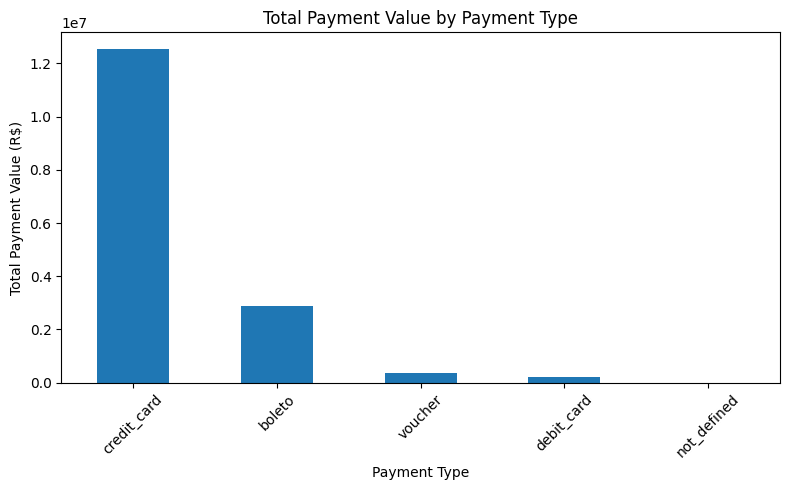

In [18]:
import os
import pandas as pd
import matplotlib.pyplot as plt

payment_file = None

for root, dirs, files in os.walk("/content/olist_data"):
    for file in files:
        if file == "olist_order_payments_dataset.csv":
            payment_file = os.path.join(root, file)
            break
    if payment_file:
        break

if payment_file:
    payments = pd.read_csv(payment_file)

    payment_summary = (
        payments.groupby("payment_type")["payment_value"]
        .sum()
        .sort_values(ascending=False)
    )

    plt.figure(figsize=(8, 5))
    payment_summary.plot(kind="bar")
    plt.title("Total Payment Value by Payment Type")
    plt.xlabel("Payment Type")
    plt.ylabel("Total Payment Value (R$)")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

else:
    print("Payment dataset not found. Send me the filenames printed after extraction.")

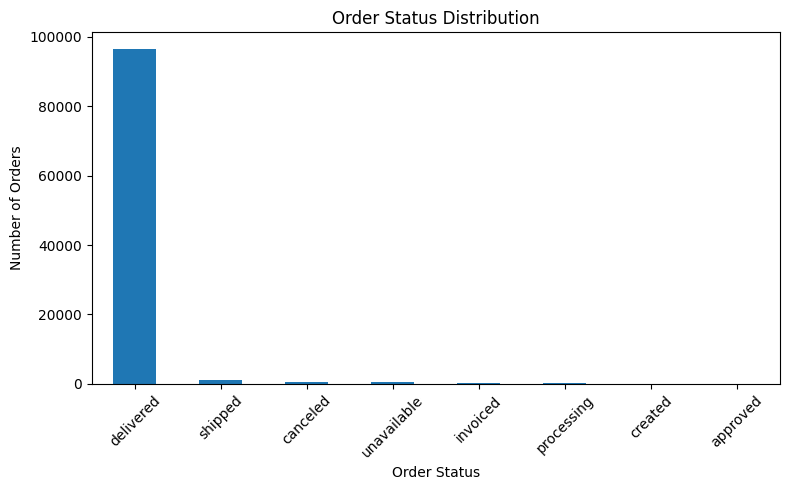

In [19]:
import os
import pandas as pd
import matplotlib.pyplot as plt

orders_file = None

for root, dirs, files in os.walk("/content/olist_data"):
    for file in files:
        if file == "olist_orders_dataset.csv":
            orders_file = os.path.join(root, file)
            break
    if orders_file:
        break

if orders_file:
    orders = pd.read_csv(orders_file)

    status_counts = orders["order_status"].value_counts()

    plt.figure(figsize=(8, 5))
    status_counts.plot(kind="bar")
    plt.title("Order Status Distribution")
    plt.xlabel("Order Status")
    plt.ylabel("Number of Orders")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
else:
    print("Orders dataset not found. Tell me what files you see.")

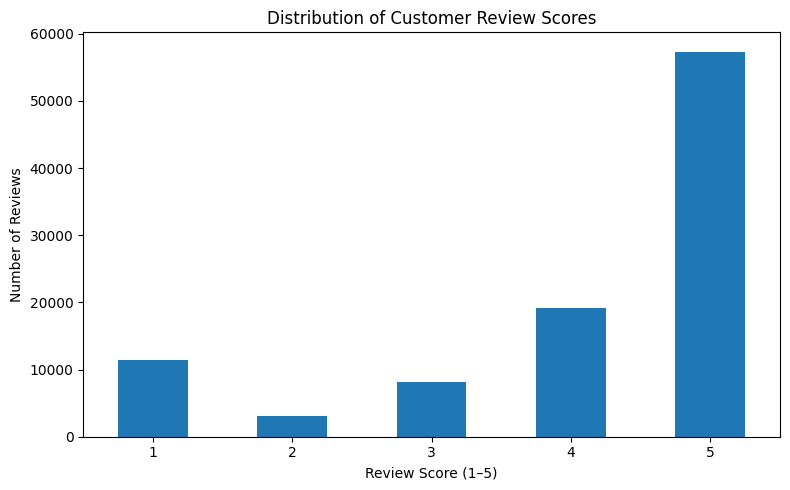

In [20]:
import os
import pandas as pd
import matplotlib.pyplot as plt

reviews_file = None

for root, dirs, files in os.walk("/content/olist_data"):
    for file in files:
        if file == "olist_order_reviews_dataset.csv":
            reviews_file = os.path.join(root, file)
            break
    if reviews_file:
        break

if reviews_file:
    reviews = pd.read_csv(reviews_file)

    review_counts = reviews["review_score"].value_counts().sort_index()

    review_counts.plot(kind="bar", figsize=(8, 5))
    plt.title("Distribution of Customer Review Scores")
    plt.xlabel("Review Score (1–5)")
    plt.ylabel("Number of Reviews")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()
else:
    print("Review dataset not found.")

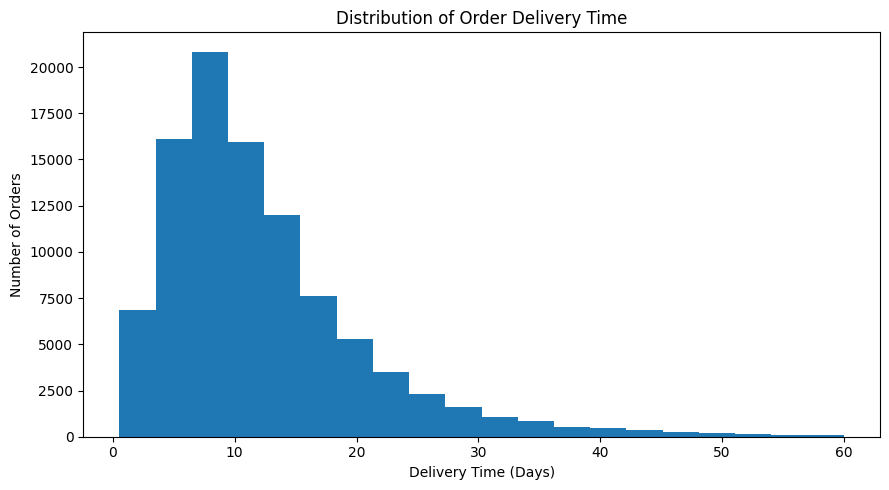

In [21]:
import os
import pandas as pd
import matplotlib.pyplot as plt

orders_file = None

for root, dirs, files in os.walk("/content/olist_data"):
    for file in files:
        if file == "olist_orders_dataset.csv":
            orders_file = os.path.join(root, file)
            break
    if orders_file:
        break

if orders_file:
    orders = pd.read_csv(orders_file)

    orders["order_purchase_timestamp"] = pd.to_datetime(
        orders["order_purchase_timestamp"], errors="coerce"
    )
    orders["order_delivered_customer_date"] = pd.to_datetime(
        orders["order_delivered_customer_date"], errors="coerce"
    )

    orders["delivery_days"] = (
        orders["order_delivered_customer_date"]
        - orders["order_purchase_timestamp"]
    ).dt.total_seconds() / 86400

    delivery = orders.loc[
        orders["delivery_days"].between(0, 60), "delivery_days"
    ].dropna()

    plt.figure(figsize=(9, 5))
    plt.hist(delivery, bins=20)
    plt.title("Distribution of Order Delivery Time")
    plt.xlabel("Delivery Time (Days)")
    plt.ylabel("Number of Orders")
    plt.tight_layout()
    plt.show()
else:
    print("Orders dataset not found.")

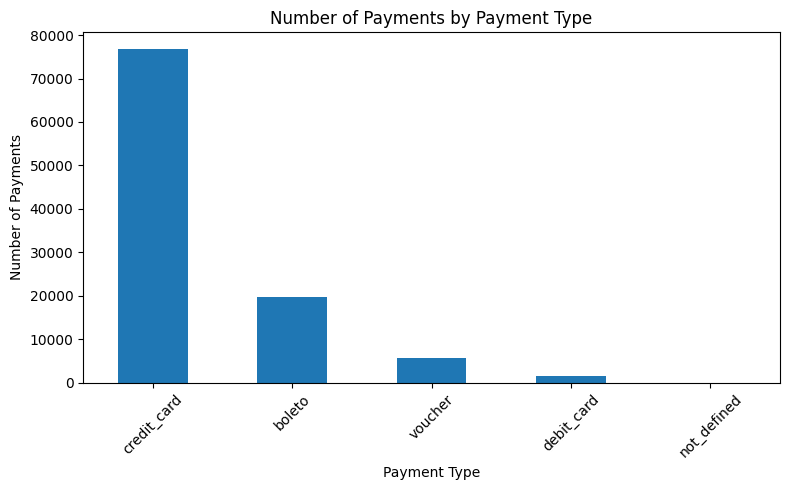

In [22]:
import os
import pandas as pd
import matplotlib.pyplot as plt

payment_file = None

for root, dirs, files in os.walk("/content/olist_data"):
    for file in files:
        if file == "olist_order_payments_dataset.csv":
            payment_file = os.path.join(root, file)
            break
    if payment_file:
        break

if payment_file:
    payments = pd.read_csv(payment_file)

    payment_counts = payments["payment_type"].value_counts()

    plt.figure(figsize=(8, 5))
    payment_counts.plot(kind="bar")
    plt.title("Number of Payments by Payment Type")
    plt.xlabel("Payment Type")
    plt.ylabel("Number of Payments")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
else:
    print("Payment dataset not found. Tell me what files you see.")

In [23]:
import os
import pandas as pd

base = "/content/olist_data/"

# Find CSV files, including files inside subfolders
csv_files = {}
for root, dirs, files in os.walk(base):
    for file in files:
        if file.endswith(".csv"):
            csv_files[file] = os.path.join(root, file)

print("Available datasets:")
for file in csv_files:
    print(file)

Available datasets:
olist_order_reviews_dataset.csv
olist_sellers_dataset.csv
product_category_name_translation.csv
olist_geolocation_dataset.csv
olist_orders_dataset.csv
olist_customers_dataset.csv
olist_order_items_dataset.csv
olist_products_dataset.csv
olist_order_payments_dataset.csv


In [24]:
import os
import pandas as pd

base = "/content/olist_data/"

csv_files = {}
for root, dirs, files in os.walk(base):
    for file in files:
        if file.endswith(".csv"):
            csv_files[file] = os.path.join(root, file)

print("Total CSV files found:", len(csv_files))
print("\nFiles:")
for file in sorted(csv_files):
    print(file)

Total CSV files found: 9

Files:
olist_customers_dataset.csv
olist_geolocation_dataset.csv
olist_order_items_dataset.csv
olist_order_payments_dataset.csv
olist_order_reviews_dataset.csv
olist_orders_dataset.csv
olist_products_dataset.csv
olist_sellers_dataset.csv
product_category_name_translation.csv


In [25]:
import os
import pandas as pd

base = "/content/olist_data"

def find_csv(keyword):
    for root, dirs, files in os.walk(base):
        for file in files:
            if keyword in file.lower() and file.endswith(".csv"):
                return os.path.join(root, file)
    return None

orders = pd.read_csv(find_csv("orders_dataset"))
items = pd.read_csv(find_csv("order_items_dataset"))
reviews = pd.read_csv(find_csv("order_reviews_dataset"))
payments = pd.read_csv(find_csv("order_payments_dataset"))
products = pd.read_csv(find_csv("products_dataset"))


orders["order_purchase_timestamp"] = pd.to_datetime(
    orders["order_purchase_timestamp"], errors="coerce"
)
monthly = (
    orders.dropna(subset=["order_purchase_timestamp"])
    .groupby(orders["order_purchase_timestamp"].dt.to_period("M"))
    .size()
)
print("\nINSIGHT 1 — Monthly orders")
print("Highest-order month:", monthly.idxmax(), "| Orders:", monthly.max())


sales = items.merge(
    products[["product_id", "product_category_name"]],
    on="product_id", how="left"
)
category = sales.groupby("product_category_name")["price"].sum().sort_values(ascending=False)
print("\nINSIGHT 2 — Top product category by item revenue")
print(category.head(5))


print("\nINSIGHT 3 — Order status")
print(orders["order_status"].value_counts())


print("\nINSIGHT 4 — Review scores")
print(reviews["review_score"].value_counts().sort_index())


print("\nINSIGHT 5 — Payment methods")
print(payments.groupby("payment_type")["payment_value"].agg(
    ["count", "sum"]
).sort_values("sum", ascending=False))


INSIGHT 1 — Monthly orders
Highest-order month: 2017-11 | Orders: 7544

INSIGHT 2 — Top product category by item revenue
product_category_name
beleza_saude              1258681.34
relogios_presentes        1205005.68
cama_mesa_banho           1036988.68
esporte_lazer              988048.97
informatica_acessorios     911954.32
Name: price, dtype: float64

INSIGHT 3 — Order status
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

INSIGHT 4 — Review scores
review_score
1    11424
2     3151
3     8179
4    19142
5    57328
Name: count, dtype: int64

INSIGHT 5 — Payment methods
              count          sum
payment_type                    
credit_card   76795  12542084.19
boleto        19784   2869361.27
voucher        5775    379436.87
debit_card     1529    217989.79
not_defined       3         0.00


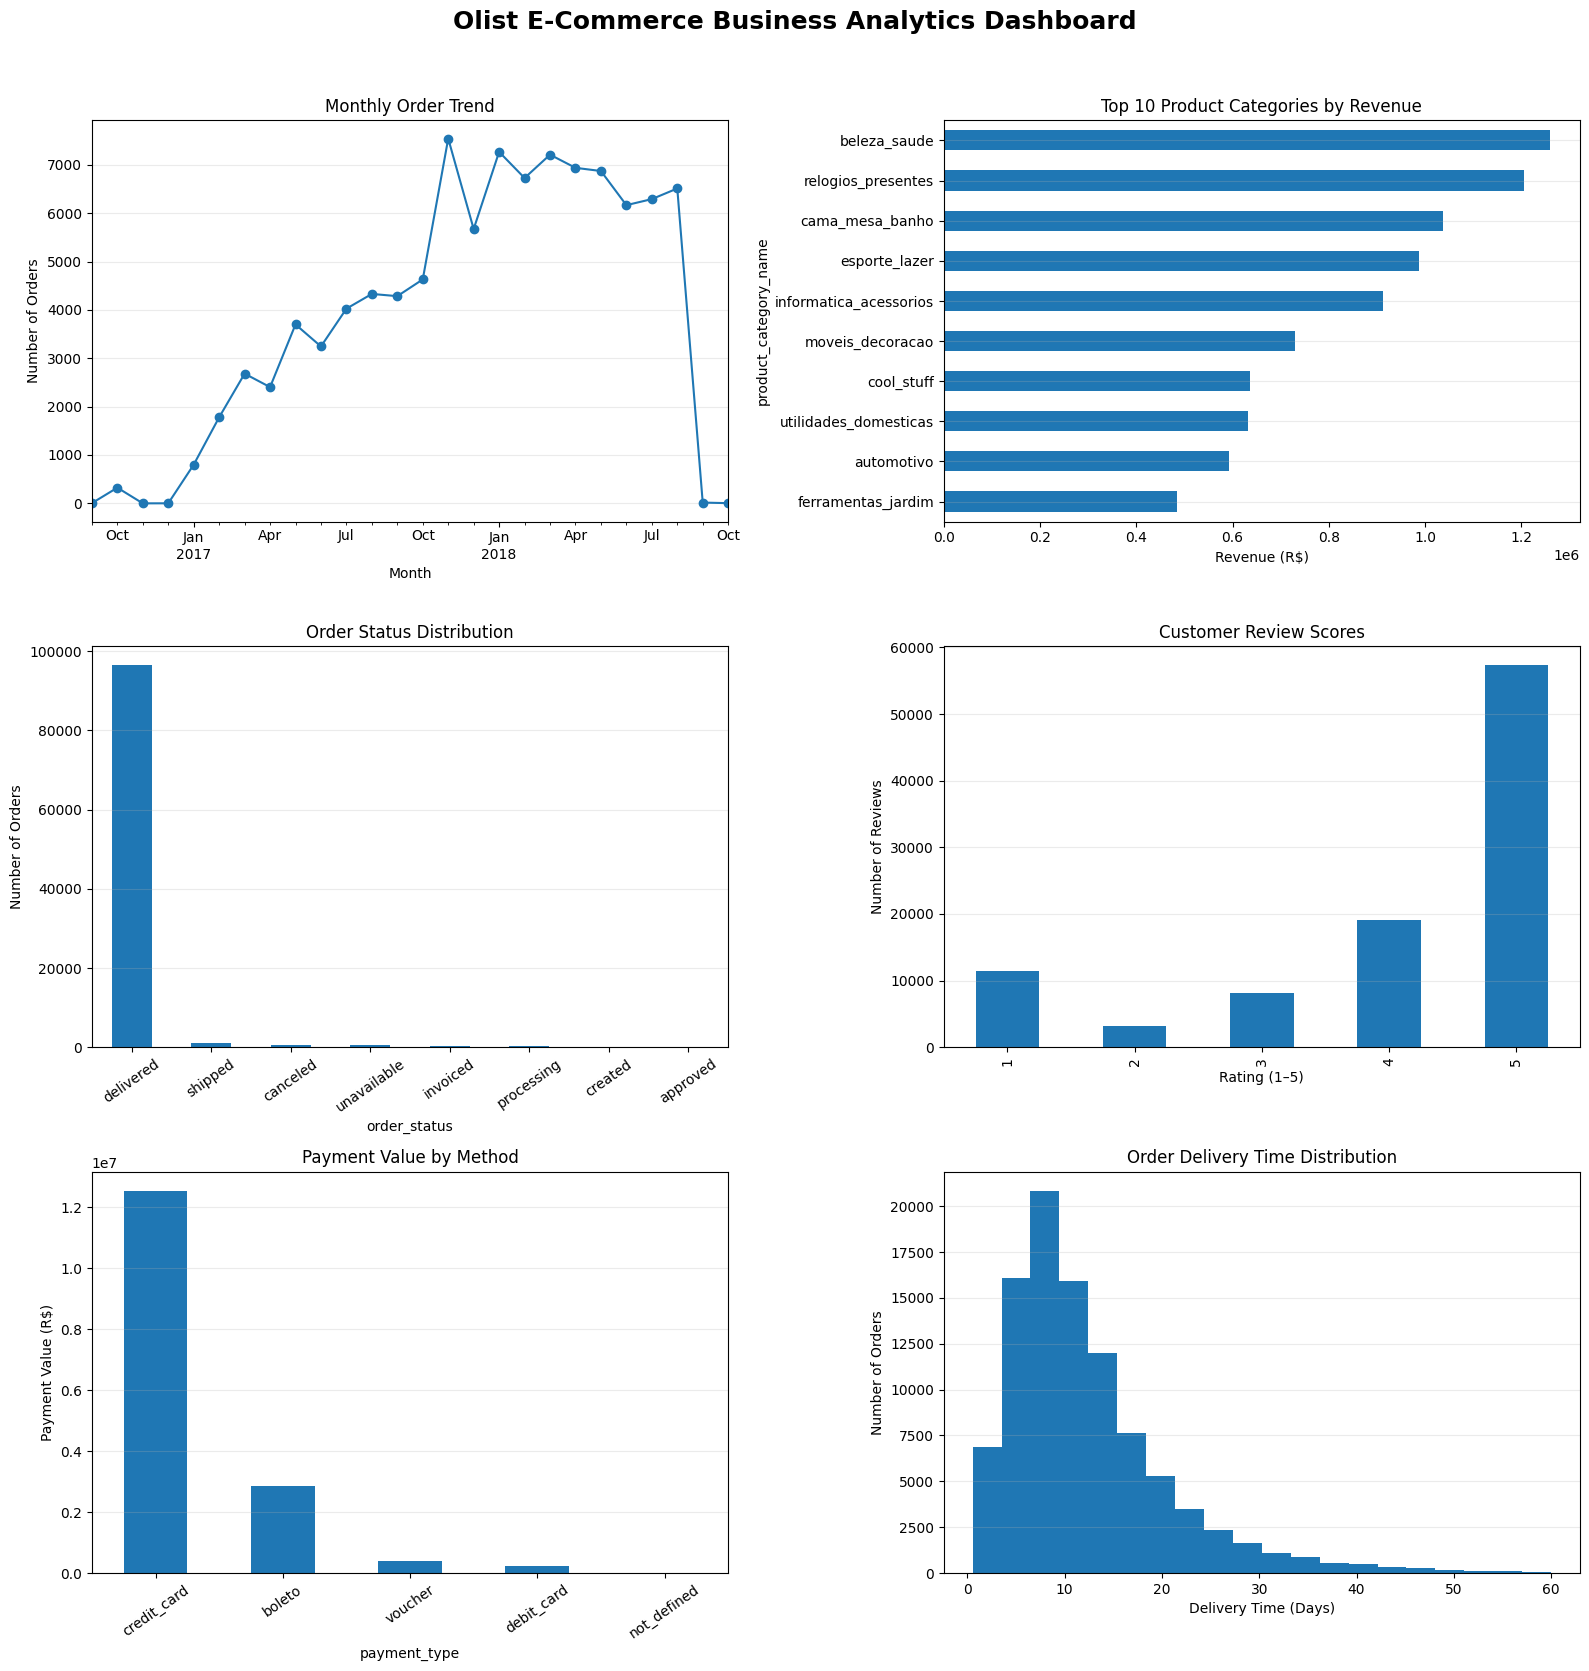

Dashboard created and saved successfully!


In [26]:
import os
import pandas as pd
import matplotlib.pyplot as plt

base = "/content/olist_data"

def get_file(keyword):
    for root, dirs, files in os.walk(base):
        for f in files:
            if keyword in f.lower() and f.endswith(".csv"):
                return os.path.join(root, f)
    raise FileNotFoundError(f"Cannot find {keyword}")

orders = pd.read_csv(get_file("orders_dataset"))
items = pd.read_csv(get_file("order_items_dataset"))
products = pd.read_csv(get_file("products_dataset"))
reviews = pd.read_csv(get_file("order_reviews_dataset"))
payments = pd.read_csv(get_file("order_payments_dataset"))

orders["order_purchase_timestamp"] = pd.to_datetime(
    orders["order_purchase_timestamp"], errors="coerce"
)
orders["order_delivered_customer_date"] = pd.to_datetime(
    orders["order_delivered_customer_date"], errors="coerce"
)

sales = items.merge(
    products[["product_id", "product_category_name"]],
    on="product_id", how="left"
)

monthly = (
    orders.dropna(subset=["order_purchase_timestamp"])
    .set_index("order_purchase_timestamp")
    .resample("MS")["order_id"].count()
)

category_revenue = (
    sales.groupby("product_category_name")["price"]
    .sum().nlargest(10).sort_values()
)

status = orders["order_status"].value_counts()
review_scores = reviews["review_score"].value_counts().sort_index()
payment_counts = payments["payment_type"].value_counts()

delivery_days = (
    orders["order_delivered_customer_date"]
    - orders["order_purchase_timestamp"]
).dt.total_seconds() / 86400

delivery_days = delivery_days[delivery_days.between(0, 60)].dropna()

fig, axes = plt.subplots(3, 2, figsize=(16, 17))
fig.suptitle(
    "Olist E-Commerce Business Analytics Dashboard",
    fontsize=18, fontweight="bold"
)

monthly.plot(ax=axes[0, 0], marker="o")
axes[0, 0].set_title("Monthly Order Trend")
axes[0, 0].set_xlabel("Month")
axes[0, 0].set_ylabel("Number of Orders")

category_revenue.plot(kind="barh", ax=axes[0, 1])
axes[0, 1].set_title("Top 10 Product Categories by Revenue")
axes[0, 1].set_xlabel("Revenue (R$)")

status.plot(kind="bar", ax=axes[1, 0])
axes[1, 0].set_title("Order Status Distribution")
axes[1, 0].set_ylabel("Number of Orders")
axes[1, 0].tick_params(axis="x", rotation=35)

review_scores.plot(kind="bar", ax=axes[1, 1])
axes[1, 1].set_title("Customer Review Scores")
axes[1, 1].set_xlabel("Rating (1–5)")
axes[1, 1].set_ylabel("Number of Reviews")

payments.groupby("payment_type")["payment_value"].sum().sort_values(
    ascending=False
).plot(kind="bar", ax=axes[2, 0])
axes[2, 0].set_title("Payment Value by Method")
axes[2, 0].set_ylabel("Payment Value (R$)")
axes[2, 0].tick_params(axis="x", rotation=35)

axes[2, 1].hist(delivery_days, bins=20)
axes[2, 1].set_title("Order Delivery Time Distribution")
axes[2, 1].set_xlabel("Delivery Time (Days)")
axes[2, 1].set_ylabel("Number of Orders")

for ax in axes.flat:
    ax.grid(axis="y", alpha=0.25)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig(
    "/content/olist_business_dashboard.png",
    dpi=200, bbox_inches="tight"
)
plt.show()

print("Dashboard created and saved successfully!")

In [27]:
from google.colab import files

files.download("/content/olist_business_dashboard.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>